# Halite solubility


**Evidence: physical comparison**, with numerical balance and complementarity
checks. At 298.15 K and 101,325 Pa, add 5, 6.5 and 7.5 mol NaCl to 1 kg water.

The liquid uses Held et al. (2014), Tables 1–3
([paper](https://doi.org/10.1016/j.cherd.2014.05.017)), specifically
`held-2014-strategy2/1`. Clarke and Glew (1985)
([paper](https://doi.org/10.1063/1.555730)), Table 34, supplies dissolution
ΔG = −9038.7 J/mol; Table 17A supplies the measured 6.1476 mol/kg solubility.
The retained PHREEQC `pitzer.dat` record supplies 27.1 × 10⁻⁶ m³/mol solid
molar volume, as documented in the existing halite reference case.


## Read the inputs

Use a repository checkout with the environment described in the installation
guide. The wheel alone does not contain these data. All density, association,
equilibrium and parameter-fit iterations below run in the native Engine.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from epcsaft import (
    Parameters,
    Mixture,
)
from epcsaft import equilibrium as eq

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

ROOT = next(
    folder
    for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / "ARCHITECTURE.yaml").is_file()
)
PACKETS = ROOT / "data" / "packets"


def equilibrium_values(solved):
    """Keep the returned physical state and the equation residuals together."""
    assert solved.success, solved.message
    assert solved.requested_tolerance_met
    assert solved.classified_residuals
    residual = max(map(abs, solved.classified_residuals), default=0)
    assert residual <= 1e-10
    return dict(
        temperature_K=solved.temperature,
        pressure_Pa=solved.pressure,
        amounts_mol=solved.amounts,
        mole_fractions=solved.mole_fractions,
        molar_densities_mol_m3=solved.molar_densities,
        residual=residual,
        linear_solver=solved.linear_solver,
    )


## Declare a stoichiometric solid

NaCl(s) contains one sodium ion and one chloride ion. The source standard is
infinite dilution on a 1 mol/kg molality basis at 101,325 Pa. Declare the
accepted scalar ln K = 3.6461705031852696 only at 298.15 K; no temperature law
is inferred. The Engine owns reference conversion and solid complementarity.

For each feed, require sodium plus solid balance within 10⁻¹⁰ times feed and
classified residuals at most 10⁻¹⁰. An absent solid has negative saturation
index; each present solid must have index within 10⁻¹⁰ of zero. Saturated
liquid molalities must agree within 10⁻⁸ mol/kg. Retain the existing 3%
relative comparison with the measured solubility.


In [2]:
model = Mixture(
    Parameters.from_json(
        PACKETS / "held-2014-strategy2/1/parameters/parameters.json",
        components=["water", "sodium-cation", "chloride-anion"],
    )
)
ln_k = 3.6461705031852696
law = eq.ReactionLogPolynomial(
    ln_k, 0, 0, 0, 298.15, 298.15, 298.15, "molality-infinite-dilution"
)
solid = eq.Solid(
    "halite",
    formula={"sodium-cation": 1, "chloride-anion": 1},
    correlation=law,
    reference=eq.ReactionReference(
        eq.ReferenceSourceBasis.CommonMolalityInfiniteDilution, 101325
    ),
    molar_volume_m3_per_mol=2.71e-05,
)
solved = []
for feed in (5.0, 6.5, 7.5):
    problem = eq.Problem(
        T=298.15,
        P=101325,
        phases=[eq.Phase("L", kind="liquid")],
        solids=[solid],
        feed=eq.Molalities(
            {"sodium-cation": feed, "chloride-anion": feed},
            solvent=["water"],
            solvent_mass_kg=1,
        ),
        neutral_reference=eq.NeutralReference(
            solvent="water",
            solute_molality_ratios={"sodium-cation": 1, "chloride-anion": 1},
            standard_molality_mol_per_kg=1,
        ),
    )
    equilibrium_result = eq.solve_equilibrium(model, problem)
    solved_values = equilibrium_values(equilibrium_result)
    molality = equilibrium_result.amounts[0] * equilibrium_result.mole_fractions[1]
    assert abs(molality + equilibrium_result.solid_amounts[0] - feed) <= 1e-10 * feed
    solved_values.update(
        feed_mol_kg=feed,
        liquid_molality_mol_kg=molality,
        solid_amount_mol=equilibrium_result.solid_amounts[0],
        saturation_index=equilibrium_result.solid_affinity_decades[0],
    )
    solved.append(solved_values)
assert abs(solved[1]["liquid_molality_mol_kg"] / 6.1476 - 1) < 0.03
assert (
    abs(solved[1]["liquid_molality_mol_kg"] - solved[2]["liquid_molality_mol_kg"])
    < 1e-08
)
assert solved[0]["solid_amount_mol"] == 0 and solved[0]["saturation_index"] < 0
assert all((abs(row["saturation_index"]) < 1e-10 for row in solved[1:]))
values = dict(
    ln_K=ln_k,
    solves=solved,
    source_solubility_mol_kg=6.1476,
    relative_discrepancy=solved[1]["liquid_molality_mol_kg"] / 6.1476 - 1,
)
display(
    pd.DataFrame(solved)[
        [
            "feed_mol_kg",
            "liquid_molality_mol_kg",
            "solid_amount_mol",
            "saturation_index",
            "residual",
        ]
    ]
)


,feed_mol_kg,liquid_molality_mol_kg,solid_amount_mol,saturation_index,residual
0,5.0,5.000000,0.000000,-0.302933,1.902069e-15
1,6.5,6.298905,0.201095,0.000000,3.343514e-14
2,7.5,6.298905,1.201095,0.000000,4.074832e-15


## Show excess salt entering the solid

Each point is a computed feed case. The connecting line guides the eye.


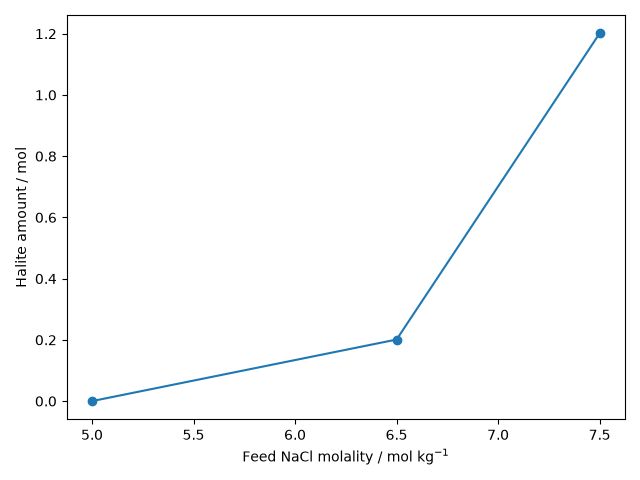

In [3]:
from io import BytesIO
from IPython.display import Image
import matplotlib.pyplot as plt

plt.plot(
    [solved["feed_mol_kg"] for solved in values["solves"]],
    [solved["solid_amount_mol"] for solved in values["solves"]],
    marker="o",
)
plt.xlabel("Feed NaCl molality / mol kg$^{-1}$")
plt.ylabel("Halite amount / mol")
buffer = BytesIO()
plt.tight_layout()
plt.savefig(buffer, format="png")
plt.close()
display(Image(data=buffer.getvalue()))


In [4]:
display(pd.DataFrame(values["solves"])[[
    "temperature_K", "pressure_Pa", "amounts_mol", "mole_fractions",
    "molar_densities_mol_m3", "linear_solver",
]].rename(columns={
            "temperature_K": "Temperature / K",
            "pressure_Pa": "Pressure / Pa",
            "amounts_mol": "Phase amounts / mol",
            "mole_fractions": "Mole fractions / 1",
            "molar_densities_mol_m3": "Phase densities / mol m^-3",
            "residual": "Maximum classified residual / 1",
            "linear_solver": "Linear solver",
        }))
display(pd.DataFrame([{
    "ln K / 1": values["ln_K"],
    "Source solubility / mol kg^-1": values["source_solubility_mol_kg"],
    "Relative discrepancy / 1": values["relative_discrepancy"],
}]))


,Temperature / K,Pressure / Pa,Phase amounts / mol,Mole fractions / 1,Phase densities / mol m^-3,Linear solver
0,298.15,101325.0,[65.50843506179199],"[0.8473479027461528, 0.07632604862692358, 0.07632604862692358]",[58395.80192102178],mumps
1,298.15,101325.0,[68.10624428000193],"[0.8150271043222239, 0.09248644783888807, 0.09248644783888807]",[59045.75616417029],mumps
2,298.15,101325.0,[68.1062442800019],"[0.815027104322224, 0.09248644783888799, 0.09248644783888799]",[59045.75616417027],mumps


,ln K / 1,Source solubility / mol kg^-1,Relative discrepancy / 1
0,3.646171,6.1476,0.024612


## Meaning and limits


The comparison covers one salt, one temperature and one source convention.
These concentrations exceed the packet's broader assessment ending at
4.5 mol/kg; the existing solubility reference case supplies this bounded use.
The 3% criterion is a comparison criterion, not a measurement uncertainty or
general salt-accuracy claim. Keep the packet's private scientific verification
use basis; this example does not relicense its source collection.
